In [1]:
import pandas as pd
import numpy as np
import os
import cv2
import matplotlib.pyplot as plt
import warnings

from tensorflow.keras import layers
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing import image, image_dataset_from_directory
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow import keras
import tensorflow as tf
from IPython.display import Image, display
import matplotlib
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.utils import class_weight

from tensorflow.keras.applications import EfficientNetB5
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization

print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

g:\Alzemer's\Alzheimer_s\venv\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


TensorFlow version: 2.20.0
GPU Available: []


In [2]:
# Set seeds for reproducibility
SEED = 54
tf.random.set_seed(SEED)
np.random.seed(SEED)
warnings.simplefilter('ignore')

In [3]:
# Configuration
IMG_SIZE = (176, 208)
BATCH_SIZE = 32
AUTOTUNE = tf.data.experimental.AUTOTUNE

# UPDATE THESE PATHS for your environment
TRAIN_DIR = r"g:\Alzemer's\Alzheimer_s\Combined Dataset\train"
TEST_DIR = r"g:\Alzemer's\Alzheimer_s\Combined Dataset\test"
MODEL_SAVE_PATH = r"g:\Alzemer's\Alzheimer_s\Models"

# Class names (alphabetical order as loaded by TensorFlow)
class_names = ['Mild Impairment', 'Moderate Impairment', 'No Impairment', 'Very Mild Impairment']
NUM_CLASSES = len(class_names)

## Load Dataset

In [4]:
# Create train and validation datasets (80% train, 20% val)
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

# Load separate test set
test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    TEST_DIR,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

print(f"Classes: {train_ds.class_names}")

Found 10240 files belonging to 4 classes.
Using 8192 files for training.
Found 10240 files belonging to 4 classes.
Using 2048 files for validation.
Found 1279 files belonging to 4 classes.
Classes: ['Mild Impairment', 'Moderate Impairment', 'No Impairment', 'Very Mild Impairment']


## Calculate Class Weights (KEY FIX!)

In [5]:
# Extract all labels from training dataset
train_labels = []
for images, labels in train_ds:
    train_labels.extend(labels.numpy())
train_labels = np.array(train_labels)

# Count samples per class
unique, counts = np.unique(train_labels, return_counts=True)
print("\n=== CLASS DISTRIBUTION ===")
for i, (cls, count) in enumerate(zip(unique, counts)):
    print(f"{class_names[int(cls)]}: {count} samples")

# Calculate balanced class weights
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)
class_weight_dict = dict(enumerate(class_weights))

print("\n=== CLASS WEIGHTS (Higher = Model pays more attention) ===")
for i, w in class_weight_dict.items():
    print(f"{class_names[i]}: {w:.4f}")


=== CLASS DISTRIBUTION ===
Mild Impairment: 2024 samples
Moderate Impairment: 2023 samples
No Impairment: 2076 samples
Very Mild Impairment: 2069 samples

=== CLASS WEIGHTS (Higher = Model pays more attention) ===
Mild Impairment: 1.0119
Moderate Impairment: 1.0124
No Impairment: 0.9865
Very Mild Impairment: 0.9899


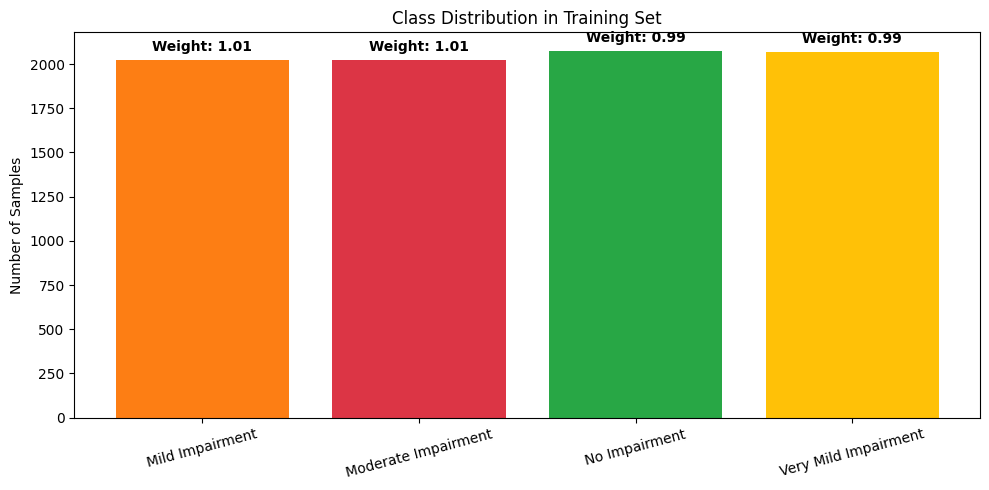

In [6]:
# Visualize class distribution
plt.figure(figsize=(10, 5))
plt.bar(class_names, counts, color=['#fd7e14', '#dc3545', '#28a745', '#ffc107'])
plt.title('Class Distribution in Training Set')
plt.ylabel('Number of Samples')
plt.xticks(rotation=15)
for i, (count, weight) in enumerate(zip(counts, class_weights)):
    plt.text(i, count + 50, f'Weight: {weight:.2f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

## Prepare Datasets

In [7]:
def one_hot_label(image, label):
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

# Apply one-hot encoding and prefetch
train_ds_prefetch = train_ds.map(one_hot_label, num_parallel_calls=AUTOTUNE).cache().prefetch(buffer_size=AUTOTUNE)
val_ds_prefetch = val_ds.map(one_hot_label, num_parallel_calls=AUTOTUNE).cache().prefetch(buffer_size=AUTOTUNE)
test_ds_prefetch = test_ds.map(one_hot_label, num_parallel_calls=AUTOTUNE).cache().prefetch(buffer_size=AUTOTUNE)

## Build Improved Model

In [8]:
def efficientnetb5_improved():
    """EfficientNetB5 with improved classification head"""
    base_model = EfficientNetB5(
        input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3), 
        weights='imagenet', 
        include_top=False
    )
    
    # Freeze base model
    for layer in base_model.layers:
        layer.trainable = False
    
    # Improved classification head
    x = GlobalAveragePooling2D()(base_model.output)
    x = BatchNormalization()(x)
    x = Dense(1024, activation='relu')(x)
    x = Dropout(0.5)(x)  # Increased dropout
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.4)(x)
    x = Dense(256, activation='relu')(x)  # Added extra layer
    x = Dropout(0.3)(x)
    output = Dense(NUM_CLASSES, activation='softmax')(x)
    
    return Model(inputs=base_model.input, outputs=output)

model = efficientnetb5_improved()
print(f"Total layers: {len(model.layers)}")
print(f"Total parameters: {model.count_params():,}")

Total layers: 586
Total parameters: 31,277,051


## Phase 1: Train with Frozen Base + Class Weights

In [9]:
EPOCHS_PHASE1 = 15

# Callbacks
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-7
)

# Compile
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.losses.CategoricalCrossentropy(label_smoothing=0.1),  # Label smoothing helps!
    metrics=[keras.metrics.AUC(name='auc'), 'acc']
)

print("=" * 50)
print("PHASE 1: Training with frozen base + CLASS WEIGHTS")
print("=" * 50)

# Train with class weights!
history1 = model.fit(
    train_ds_prefetch,
    epochs=EPOCHS_PHASE1,
    validation_data=val_ds_prefetch,
    callbacks=[early_stop, reduce_lr],
    class_weight=class_weight_dict  # <-- KEY FIX!
)

# Save Phase 1
model.save(os.path.join(MODEL_SAVE_PATH, 'efficientnetb5_phase1_weighted.h5'))
print("Phase 1 model saved!")

PHASE 1: Training with frozen base + CLASS WEIGHTS
Epoch 1/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 1101s 4s/step - acc: 0.5343 - auc: 0.7907 - loss: 1.2668 - val_acc: 0.6895 - val_auc: 0.9210 - val_loss: 1.0060 - learning_rate: 0.0010
Epoch 2/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 995s 4s/step - acc: 0.6492 - auc: 0.8896 - loss: 0.9461 - val_acc: 0.7300 - val_auc: 0.9364 - val_loss: 0.8156 - learning_rate: 0.0010
Epoch 3/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 903s 4s/step - acc: 0.6897 - auc: 0.9106 - loss: 0.8863 - val_acc: 0.7534 - val_auc: 0.9448 - val_loss: 0.7823 - learning_rate: 0.0010
Epoch 4/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 889s 3s/step - acc: 0.6957 - auc: 0.9178 - loss: 0.8635 - val_acc: 0.7593 - val_auc: 0.9499 - val_loss: 0.7513 - learning_rate: 0.0010
Epoch 5/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 814s 3s/step - acc: 0.7123 - auc: 0.9229 - loss: 0.8454 - val_acc: 0.7695 - val_auc: 0.9554 - val_loss: 0.7315 - learning_rate: 0.0010
Epoch 6/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 829s 3s/step - acc: 0.7262 - auc:

Phase 1 model saved!


## Phase 2: Fine-tune Last Layers

In [10]:
EPOCHS_PHASE2 = 15

# Unfreeze last 50 layers for fine-tuning
for layer in model.layers[-50:]:
    if not isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = True

# Recompile with lower learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=[keras.metrics.AUC(name='auc'), 'acc']
)

print("=" * 50)
print("PHASE 2: Fine-tuning with CLASS WEIGHTS")
print("=" * 50)

history2 = model.fit(
    train_ds_prefetch,
    epochs=EPOCHS_PHASE2,
    validation_data=val_ds_prefetch,
    callbacks=[early_stop, reduce_lr],
    class_weight=class_weight_dict  # <-- KEY FIX!
)

# Save final model
model.save(os.path.join(MODEL_SAVE_PATH, 'efficientnetb5_weighted_final.h5'))
print("\n✓ Final model saved as: efficientnetb5_weighted_final.h5")

PHASE 2: Fine-tuning with CLASS WEIGHTS
Epoch 1/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 960s 4s/step - acc: 0.7966 - auc: 0.9581 - loss: 0.7260 - val_acc: 0.8247 - val_auc: 0.9731 - val_loss: 0.6475 - learning_rate: 1.0000e-05
Epoch 2/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 3716s 15s/step - acc: 0.8041 - auc: 0.9620 - loss: 0.7092 - val_acc: 0.8208 - val_auc: 0.9720 - val_loss: 0.6508 - learning_rate: 1.0000e-05
Epoch 3/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 858s 3s/step - acc: 0.8079 - auc: 0.9635 - loss: 0.7022 - val_acc: 0.8311 - val_auc: 0.9750 - val_loss: 0.6387 - learning_rate: 1.0000e-05
Epoch 4/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 851s 3s/step - acc: 0.8158 - auc: 0.9659 - loss: 0.6923 - val_acc: 0.8315 - val_auc: 0.9754 - val_loss: 0.6354 - learning_rate: 1.0000e-05
Epoch 5/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 847s 3s/step - acc: 0.8185 - auc: 0.9670 - loss: 0.6866 - val_acc: 0.8389 - val_auc: 0.9767 - val_loss: 0.6288 - learning_rate: 1.0000e-05
Epoch 6/15
256/256 ━━━━━━━━━━━━━━━━━━━━ 863s 3s/step - acc: 0.8


✓ Final model saved as: efficientnetb5_weighted_final.h5


## Plot Training History

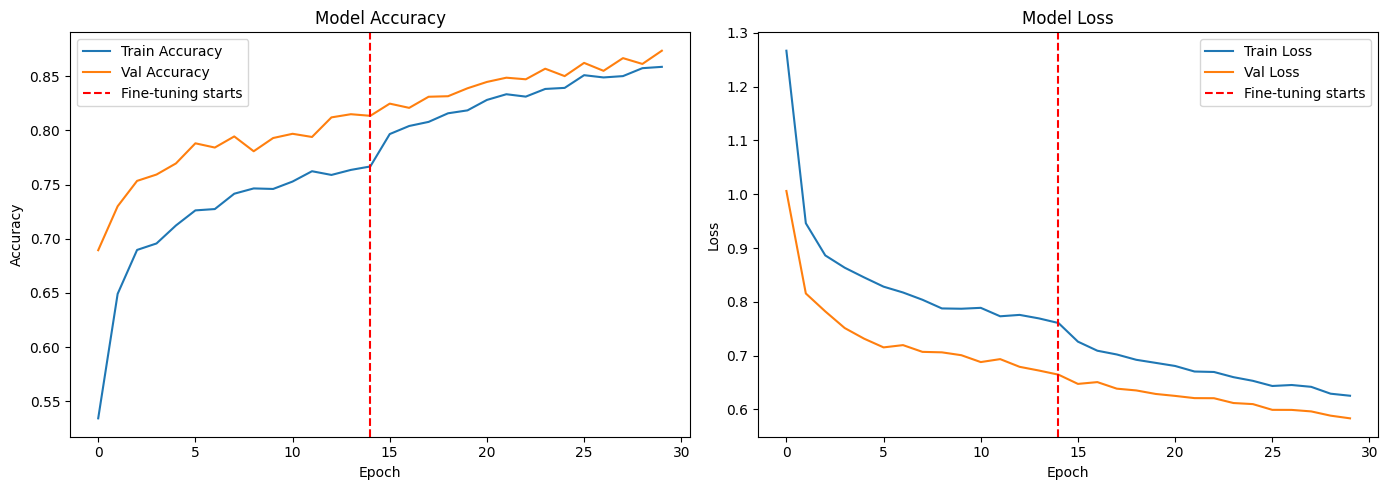

In [11]:
# Combine histories
acc = history1.history['acc'] + history2.history['acc']
val_acc = history1.history['val_acc'] + history2.history['val_acc']
loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(acc, label='Train Accuracy')
axes[0].plot(val_acc, label='Val Accuracy')
axes[0].axvline(x=len(history1.history['acc'])-1, color='r', linestyle='--', label='Fine-tuning starts')
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

# Loss
axes[1].plot(loss, label='Train Loss')
axes[1].plot(val_loss, label='Val Loss')
axes[1].axvline(x=len(history1.history['loss'])-1, color='r', linestyle='--', label='Fine-tuning starts')
axes[1].set_title('Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(MODEL_SAVE_PATH, 'training_history.png'), dpi=150)
plt.show()

## Evaluate on Test Set

In [12]:
print("=" * 50)
print("EVALUATION ON TEST SET")
print("=" * 50)

# Evaluate
results = model.evaluate(test_ds_prefetch, verbose=1)
print(f"\nTest Loss: {results[0]:.4f}")
print(f"Test AUC: {results[1]:.4f}")
print(f"Test Accuracy: {results[2]:.4f}")

EVALUATION ON TEST SET
40/40 ━━━━━━━━━━━━━━━━━━━━ 112s 3s/step - acc: 0.7404 - auc: 0.9344 - loss: 0.8019

Test Loss: 0.8019
Test AUC: 0.9344
Test Accuracy: 0.7404


In [13]:
# Get predictions
y_pred = model.predict(test_ds_prefetch, verbose=1)
predicted_categories = tf.argmax(y_pred, axis=1).numpy()

# Get true labels
true_categories = tf.concat([y for x, y in test_ds_prefetch], axis=0)
true_categories = tf.argmax(true_categories, axis=1).numpy()

# Classification Report
print("\n" + "=" * 50)
print("CLASSIFICATION REPORT")
print("=" * 50)
print(classification_report(true_categories, predicted_categories, target_names=class_names))

40/40 ━━━━━━━━━━━━━━━━━━━━ 110s 3s/step

CLASSIFICATION REPORT
                      precision    recall  f1-score   support

     Mild Impairment       0.85      0.53      0.65       179
 Moderate Impairment       0.92      1.00      0.96        12
       No Impairment       0.76      0.88      0.82       640
Very Mild Impairment       0.67      0.62      0.65       448

            accuracy                           0.74      1279
           macro avg       0.80      0.76      0.77      1279
        weighted avg       0.74      0.74      0.73      1279



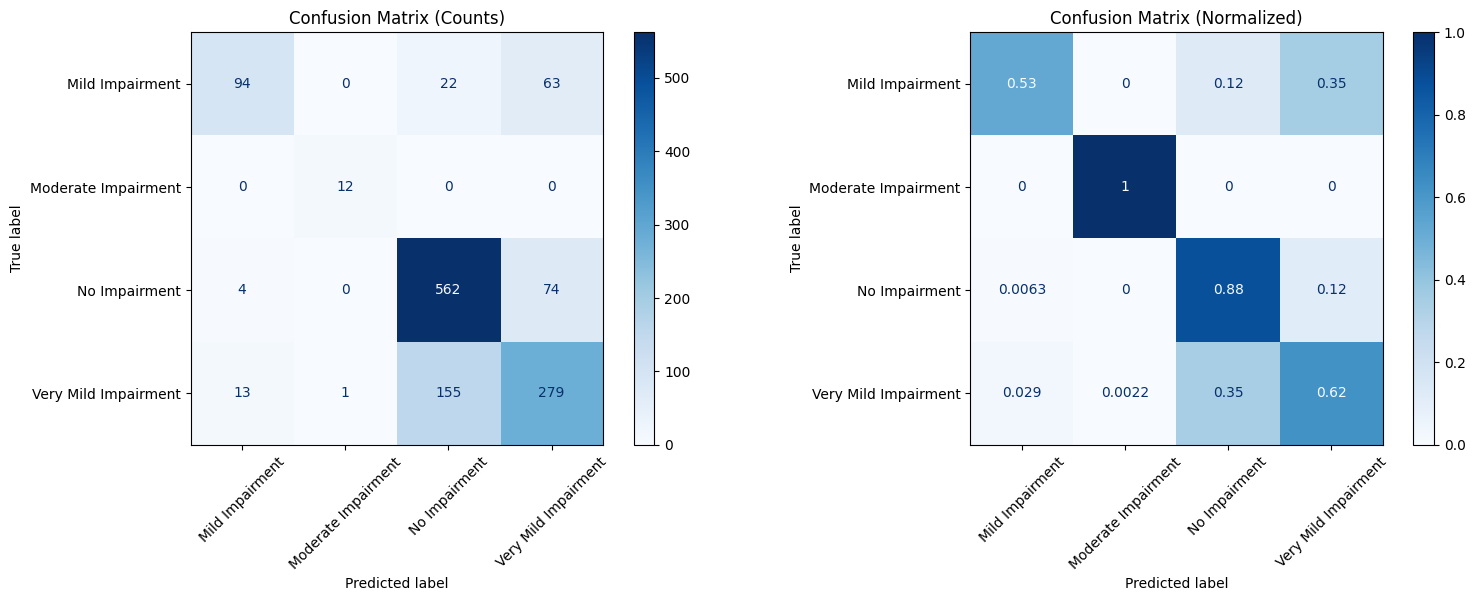


✓ Confusion matrix saved!


In [14]:
# Confusion Matrix
cm = confusion_matrix(true_categories, predicted_categories)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Raw counts
disp1 = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp1.plot(ax=axes[0], cmap=plt.cm.Blues, xticks_rotation=45)
axes[0].set_title('Confusion Matrix (Counts)')

# Normalized
disp2 = ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=class_names)
disp2.plot(ax=axes[1], cmap=plt.cm.Blues, xticks_rotation=45)
axes[1].set_title('Confusion Matrix (Normalized)')

plt.tight_layout()
plt.savefig(os.path.join(MODEL_SAVE_PATH, 'confusion_matrix_weighted1.png'), dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ Confusion matrix saved!")

## Compare: Before vs After Class Weighting

In [15]:
# Per-class accuracy
print("\n=== PER-CLASS ACCURACY ===")
for i, name in enumerate(class_names):
    class_mask = true_categories == i
    class_acc = (predicted_categories[class_mask] == i).mean() * 100
    print(f"{name}: {class_acc:.1f}%")


=== PER-CLASS ACCURACY ===
Mild Impairment: 52.5%
Moderate Impairment: 100.0%
No Impairment: 87.8%
Very Mild Impairment: 62.3%
